# Day 04 — Why linear algebra? Two problems from the course

Videos:
- LA M1 › 01 › 01 *Introduction: solving data science challenges with mathematics*
- LA M1 › 02 › 01 *Motivations for linear algebra*
- LA M1 › 02 › 02 *Getting a handle on vectors*

**Goal:** rebuild the two problems from the videos in code.

1. **Apples and bananas:** simultaneous equations written as a matrix times a vector.
2. **Fitting heights:** finding the best `[mu, sigma]` is finding a *point* in parameter space, and moving towards it is moving along a *vector*.

No new library function today. The notebook is the work, so make the plots clean.

In [30]:
import numpy as np
import matplotlib.pyplot as plt

from linalg.vectors import vectors_close

## Part A — Apples and bananas (video 01, *Motivations*)

Trip 1: 2 apples + 3 bananas cost 8 €. Trip 2: 10 apples + 1 banana cost 13 €. With `a` = price of an apple and `b` = price of a banana:

```
 2a + 3b =  8
10a + 1b = 13
```

In matrix form: **A p = c**, where each *row* of `A` is one shopping trip, `p = [a, b]` is the price vector, and `c` is the vector of costs.

**A1:** create the matrix `A` (shape `(2, 2)`) and the cost vector `c` (shape `(2,)`). Print both shapes.

Expected: `(2, 2)` and `(2,)`

In [31]:
A = np.array([[2, 3], [10, 1]])
print(A.shape)
c = np.array([8,13])
print(c.T.shape)


(2, 2)
(2,)


**A2 — test a guess:** guess `p = np.array([1, 2])` (apples 1 €, bananas 2 €). Compute `A @ p`, then the *residual* `A @ p - c` (how wrong each trip is).

Expected: `[ 8 12]` and `[ 0 -1]`. Trip 1 is right, trip 2 is 1 € too cheap.

In [32]:
p = np.array([1, 2])
print(A@p)
print(A@p-c)

[ 8 12]
[ 0 -1]


**A3:** try the guess `[1.5, 1.5]`.

Expected: `A @ p` = `[ 7.5 16.5]`, residual `[-0.5  3.5]`. Worse than the first guess. Guessing is slow, so we need an algorithm.

In [33]:
p = np.array([1.5, 1.5])
print(A@p)
print(A@p-c)

[ 7.5 16.5]
[-0.5  3.5]


**A4 — peek at the answer:** NumPy can solve it with `np.linalg.solve(A, c)`. (You'll write your own `solve` on Day 21, so this is just a peek.)

Expected: `[1.10714286 1.92857143]`

Then check it with **your** Day 3 function: `vectors_close(A @ p, c)` should be `True`.

In [34]:
p = np.linalg.solve(A, c)
print(p)
vectors_close(A@p, c)



[1.10714286 1.92857143]


np.True_

## Part B — Fitting a distribution (video 02, *Getting a handle on vectors*)

We measured the heights of 1000 people. We want the normal (Gaussian) curve that fits them best:

$$f(x) = \frac{1}{\sigma\sqrt{2\pi}} \exp\left(-\frac{(x-\mu)^2}{2\sigma^2}\right)$$

It has only two parameters: `mu` (the centre) and `sigma` (the width). So every possible curve is one **point** `[mu, sigma]` in a 2D *parameter space*.

Run the setup cell. It makes fake height data and a histogram. `counts` are the bar heights, `x` are the centres of the 30 bars.

In [35]:
rng = np.random.default_rng(0)
heights = rng.normal(1.70, 0.08, 1000)   # in metres

edges = np.linspace(1.4, 2.0, 31)
counts, edges = np.histogram(heights, bins=edges, density=True)
x = (edges[:-1] + edges[1:]) / 2         # centre of each bar

print(x.shape, counts.shape)


(30,) (30,)


**B1:** plot the histogram: `plt.bar(x, counts, width=0.02)`. Add axis labels (height in m, density).

Expected: a bell shape, centred around 1.70 m, highest bar a bit above 5.

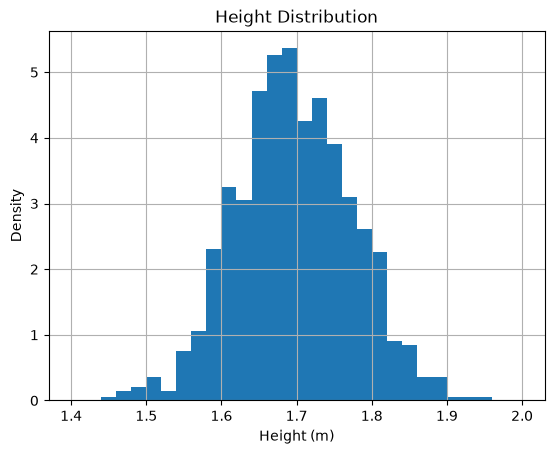

In [36]:
plt.bar(x, counts, width = 0.02)

plt.xlabel("Height (m)")
plt.ylabel("Density")
plt.title("Height Distribution")
plt.grid()
plt.show()

**B2:** write `gaussian(x, mu, sigma)` that returns the formula above. Use `np.exp`, `np.sqrt`, `np.pi`.

Check: `gaussian(1.70, 1.70, 0.08)` → `4.986778505017909` and `gaussian(1.78, 1.70, 0.08)` → `3.0246340564892895`.

In [37]:
def gaussian(x, mu, sigma):
    gauss = (1 / (sigma * np.sqrt(2 * np.pi))) * np.exp(
        -((x - mu) ** 2) / (2 * sigma**2)
    )
    return gauss

print(gaussian(1.70, 1.70, 0.08))
print(gaussian(1.78, 1.70, 0.08))


4.986778505017909
3.0246340564892895


**B3:** on top of the histogram, plot three guesses as lines (use `xs = np.linspace(1.4, 2.0, 200)`):

| guess | mu | sigma |
|---|---|---|
| good | 1.70 | 0.08 |
| too wide | 1.70 | 0.12 |
| shifted | 1.65 | 0.08 |

Add `plt.legend()`. You should see what the video says: the wide curve is too low in the middle and too high at the edges.

Text(0.5, 1.0, 'Height distribution')

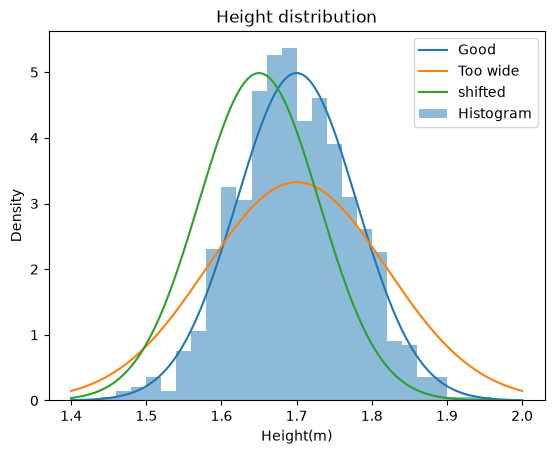

In [38]:
xs = np.linspace(1.4, 2.0, 200)

plt.bar(x, counts, width=0.02, alpha=0.5, label="Histogram")

plt.plot(xs, gaussian(xs, 1.70, 0.08), label="Good")
plt.plot(xs, gaussian(xs, 1.70, 0.12), label="Too wide")
plt.plot(xs, gaussian(xs, 1.65, 0.08), label="shifted")

plt.legend()

plt.xlabel("Height(m)")
plt.ylabel("Density")
plt.title("Height distribution")

**B4 — measure "how wrong":** write `sse(mu, sigma)`, the **sum of squared errors** between the bars and the curve:

`np.sum((counts - gaussian(x, mu, sigma)) ** 2)`

Expected:

| guess | SSE |
|---|---|
| (1.70, 0.08) | `2.7088549461353826` |
| (1.70, 0.12) | `22.103474331718477` |
| (1.65, 0.08) | `30.268879579417106` |

Smaller SSE = better fit. Fitting means: find the `[mu, sigma]` with the smallest SSE.

In [39]:
def sse(mu, sigma):
    SSE = np.sum((counts - gaussian(x, mu, sigma))**2)
    return SSE

print(sse(1.70, 0.08))
print(sse(1.70, 0.12))
print(sse(1.65, 0.08))


2.7088549461353804
22.103474331718477
30.268879579417106


## Part C — The parameter space

**Why:** this is the central picture of the video. Each point `[mu, sigma]` has an SSE value, like a height on a map. The best fit is the bottom of the valley.

**C1 — compute the map:** make a grid of parameter values and the SSE at every point:

```python
mus = np.linspace(1.60, 1.80, 101)
sigmas = np.linspace(0.04, 0.16, 121)
MU, SIGMA = np.meshgrid(mus, sigmas)
```

Fill `Z` (same shape as `MU`) with `sse(...)` for every pair. A double loop is fine, or a list comprehension.

Expected: `Z.shape` is `(121, 101)`. Rows follow sigma, columns follow mu.

In [40]:
mus = np.linspace(1.60, 1.80, 101)
sigmas = np.linspace(0.04, 0.16, 121)
MU, SIGMA = np.meshgrid(mus, sigmas)
MU.shape
#Create an empty matrix
Z = np.zeros_like(MU)

#Calculate every pair
for i in range(len(sigmas)):
    for j in range(len(mus)):
        Z[i, j] = sse(MU[i, j], SIGMA[i, j])

print(Z.shape)


(121, 101)


**C2 — draw it:** `plt.contourf(MU, SIGMA, Z, levels=50)` plus `plt.colorbar()`. Label the axes `mu` and `sigma`.

Tip: SSE varies a lot, so the valley is easier to see with `np.log(Z)` instead of `Z`.

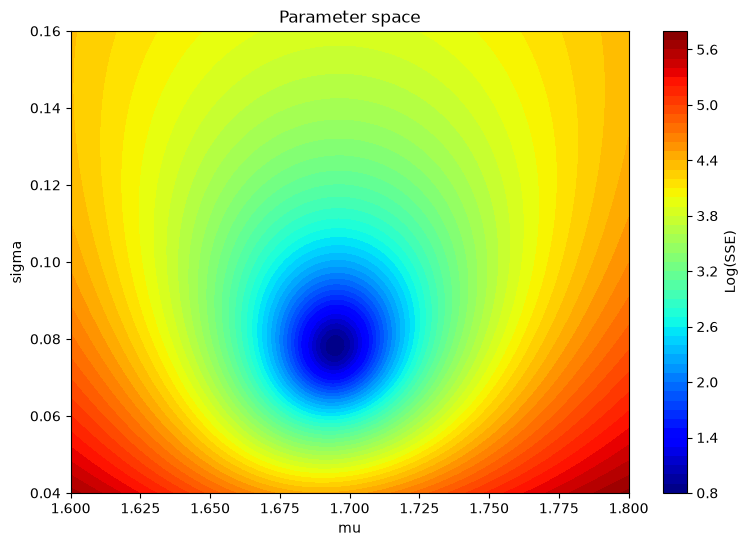

In [41]:
plt.figure(figsize=(9, 6))

plt.contourf(MU, SIGMA, np.log(Z), levels=50, cmap='jet')

plt.colorbar(label="Log(SSE)")

plt.xlabel("mu")
plt.ylabel("sigma")
plt.title("Parameter space")

plt.show()



**C3 — find the bottom:** use `Z.argmin()` and `np.unravel_index(..., Z.shape)` to find the grid point with the smallest SSE. Mark it on the plot with a red `x`.

Expected: `mu ≈ 1.694`, `sigma ≈ 0.078`, SSE ≈ `2.2697`.

Compare with `heights.mean()` and `heights.std()`: `1.6962`, `0.0781`. Close, because the best normal curve has the same centre and width as the data.

In [42]:
# Find the index of minimum SSE
i, j = np.unravel_index(Z.argmin(), Z.shape)

# Get the best parameters
best_mu = MU[i, j]
best_sigma = SIGMA[i, j]
best_sse = Z[i, j]

print("Best mu:", best_mu)
print("Best sigma:", best_sigma)
print("Best SSE:", best_sse)

print(heights.mean())
print(heights.std())

Best mu: 1.6940000000000002
Best sigma: 0.078
Best SSE: 2.2696548604906797
1.696157737858961
0.07814023698856842


## Part D — Moving downhill with vectors

**Why:** in real ML there are millions of parameters, so you can't draw the whole map. Instead you start at a guess and take small **steps** downhill. Each step is a **vector** in parameter space. This is the idea the video uses to say why vectors matter.

**D1 — the gradient:** the *gradient* is a vector that points uphill. Estimate it at `p = np.array([1.65, 0.12])` by nudging each parameter a tiny bit (`h = 1e-6`):

```python
dmu    = (sse(p[0] + h, p[1]) - sse(p[0] - h, p[1])) / (2 * h)
dsigma = (sse(p[0], p[1] + h) - sse(p[0], p[1] - h)) / (2 * h)
grad = np.array([dmu, dsigma])
```

Expected: about `[-593.3  409.06]`. Negative for mu (increasing mu goes downhill), positive for sigma (decreasing sigma goes downhill). Both match what you see on the map.

In [43]:
# Initial guess
p = np.array([1.65, 0.12])

# Small step
h = 1e-6

# Calculate partial derivative with respect to mu
dmu = (
    sse(p[0] + h, p[1]) -
    sse(p[0] - h, p[1])
) / (2 * h)

# Calculate partial derivative with respect to sigma
dsigma = (
    sse(p[0], p[1] + h) -
    sse(p[0], p[1] - h)
) / (2 * h)

# Create gradient vector
grad = np.array([dmu, dsigma])

print("Initial parameters:", p)
print("dmu:", dmu)
print("dsigma:", dsigma)
print("Gradient:", grad)

Initial parameters: [1.65 0.12]
dmu: -593.3022154174239
dsigma: 409.06170875132375
Gradient: [-593.30221542  409.06170875]


**D2 — one step:** a step downhill is `p_new = p - lr * grad` with a small *learning rate* `lr = 1e-5`.

Expected: `p_new ≈ [1.6559 0.1159]`, and `sse(*p_new)` ≈ `30.88`, lower than `sse(1.65, 0.12)` ≈ `36.07`.

`- lr * grad` is a scalar times a vector. You'll write `scale(k, v)` for exactly this on Day 5.

In [44]:
# Initial parameters
p = np.array([1.65, 0.12])

# Learning rate
lr = 1e-5

# Update parameters
p_new = p - lr * grad

print("Old parameters:", p)
print("New parameters:", p_new)

# Compare SSE before and after updating
print("Old SSE:", sse(*p))
print("New SSE:", sse(*p_new))

Old parameters: [1.65 0.12]
New parameters: [1.65593302 0.11590938]
Old SSE: 36.06954575431013
New SSE: 30.878642653284917


**D3 — walk to the bottom:** put D1 and D2 in a loop for 100 steps. Save every `p` in a list called `path`, then draw the path on top of your contour plot from C2 (`path = np.array(path)`, then `plt.plot(path[:, 0], path[:, 1], 'w.-')`).

Expected final point: about `[1.6948 0.0781]`, SSE ≈ `2.2605`, very close to the bottom you found in C3.

In [45]:
# Initial parameters
p = np.array([1.65, 0.12])

# Learning rate and small step
lr = 1e-5
h = 1e-6

# Store the parameter path
path = [p.copy()]

# Gradient Descent: 100 steps
for step in range(100):

    # D1: Calculate gradient
    dmu = (
        sse(p[0] + h, p[1]) -
        sse(p[0] - h, p[1])
    ) / (2 * h)

    dsigma = (
        sse(p[0], p[1] + h) -
        sse(p[0], p[1] - h)
    ) / (2 * h)

    grad = np.array([dmu, dsigma])

    # D2: Update parameters
    p = p - lr * grad

    # Save current parameters
    path.append(p.copy())

# Convert list to NumPy array
path = np.array(path)

# Print results
print("Final parameters:", p)
print("Final SSE:", sse(*p))
print("Path shape:", path.shape)

Final parameters: [1.69477256 0.07814395]
Final SSE: 2.2605414994055115
Path shape: (101, 2)


**D4 — experiment:** run D3 again with `lr = 5e-5`. Where does it end? Plot the path.

Expected: it does **not** settle (around `sigma ≈ 0.07`, SSE ≈ `3.83`). Steps that are too big overshoot the valley. Write one sentence about why in your notes.

## Check yourself

Answer in a **Markdown** cell below (**+ Markdown**).

- In `A p = c`, what does each row of `A` represent? What does `p` represent?
- What is a *residual*, and what does a residual of `[0, 0]` mean?
- Why is fitting `mu` and `sigma` the same as finding a point in a 2D space?
- What does the gradient vector tell you, and why do we step in the *opposite* direction?
- What goes wrong when the learning rate is too large?